In [18]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Change to project directory
os.chdir('/Users/apple/Downloads/HUTECH/Thesis/FOTA_project')
print(f"Working directory: {os.getcwd()}")

Working directory: /Users/apple/Downloads/HUTECH/Thesis/FOTA_project


In [30]:
import shutil
plt.rcParams.update({
    "text.usetex": shutil.which('latex') is not None,            
    "font.family": "serif",         
    "font.size": 10,                # Size text cơ bản là 10pt
    "axes.labelsize": 10,           # Label trục 10pt
    "xtick.labelsize": 10,          # Số đo trục X 10pt
    "ytick.labelsize": 10,          # Số đo trục Y 10pt
    "legend.fontsize": 9,           # Chú thích nhỏ hơn một chút
})

In [20]:
# Configuration parameters (Benign Sample)
SR = 22050           # Sample rate
HOP_LENGTH = 256     # Hop length
WIN_LENGTH = 1024    # Window length
N_FFT = 1024         # FFT size
N_MELS = 80          # Number of mel bands

# Paths
TRAIN_NPY_PATH = './datasets/npy_scd10/train/'
TRAIN_WAV_PATH = './datasets/raw/train/'

print(f"Configuration:")
print(f"  SR: {SR} Hz")
print(f"  Hop Length: {HOP_LENGTH}")
print(f"  N_FFT: {N_FFT}")
print(f"  N_Mels: {N_MELS}")

Configuration:
  SR: 22050 Hz
  Hop Length: 256
  N_FFT: 1024
  N_Mels: 80


In [21]:
# Load first left sample from NPY files
left_npy_dir = os.path.join(TRAIN_NPY_PATH, 'left')
npy_files = sorted([f for f in os.listdir(left_npy_dir) if f.endswith('.npy')])

print(f"Found {len(npy_files)} NPY files in {left_npy_dir}")

# Load the first file
first_npy_file = npy_files[0]
npy_path = os.path.join(left_npy_dir, first_npy_file)
mel_spec_data = np.load(npy_path)

mel_spec_data.shape

print(f"\nFirst NPY file: {first_npy_file}")
print(f"  Path: {npy_path}")
print(f"  Shape: {mel_spec_data.shape}")
print(f"  - Channels: {mel_spec_data.shape[0]}")
print(f"  - Mel bands: {mel_spec_data.shape[1]}")
print(f"  - Time frames: {mel_spec_data.shape[2]}")
print(f"  Data type: {mel_spec_data.dtype}")
print(f"  Value range: [{mel_spec_data.min():.2f}, {mel_spec_data.max():.2f}] dB")

Found 1839 NPY files in ./datasets/npy_scd10/train/left

First NPY file: 00176480_nohash_0.npy
  Path: ./datasets/npy_scd10/train/left/00176480_nohash_0.npy
  Shape: (1, 80, 87)
  - Channels: 1
  - Mel bands: 80
  - Time frames: 87
  Data type: float32
  Value range: [-58.08, 21.92] dB


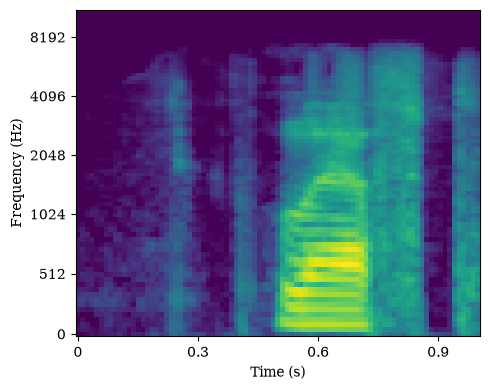


Shape: (80, 87) (mel_bands, time_frames)
Data type: float32
Value range: [-58.08, 21.92] dB


In [31]:
import matplotlib.pyplot as plt
import numpy as np
import librosa.display

# Use the already-loaded mel_spec_data if present, otherwise load from npy_path
try:
    sample_data = mel_spec_data
except NameError:
    sample_data = np.load(npy_path)

# Remove channel dimension if present
mel_spec = np.squeeze(sample_data)
if mel_spec.ndim == 3 and mel_spec.shape[0] == 1:
    mel_spec = mel_spec.squeeze(0)

# Ensure mel_spec is shape (n_mels, time)
if mel_spec.ndim != 2:
    raise ValueError(f"Expected 2D mel-spectrogram, got shape {mel_spec.shape}")

fig, ax = plt.subplots(figsize=(5, 4))
librosa.display.specshow(mel_spec, sr=SR, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', fmax=SR/2, cmap='viridis')

# cbar = plt.colorbar(format='%+2.0f dB')
# cbar.set_label('Power (dB)')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_xticks([0, 0.3, 0.6, 0.9])
ax.set_yticks([0, 512, 1024, 2048, 4096, 8192])
# plt.title(f'Mel-Spectrogram: {first_npy_file}')
plt.tight_layout()
plt.show()

print(f"\nShape: {mel_spec.shape} (mel_bands, time_frames)")
print(f"Data type: {mel_spec.dtype}")
print(f"Value range: [{mel_spec.min():.2f}, {mel_spec.max():.2f}] dB")
